# Iris classification

Inspect the UCI Iris dataset (id 53). Each row is one flower: four measurements in centimeters, and one of three species (`Iris-setosa`, `Iris-versicolor`, `Iris-virginica`).

A logistic regression is the baseline.

K-nearest neighbors (k = 5) and a decision tree are then fit on the same flowers. Stratified 5-fold cross-validation checks all three on the training flowers.


## Trust the dataset download

`ucimlrepo` checks the UCI server with the `certifi` certificate bundle. On this machine Avast Web/Mail Shield scans HTTPS, so the server certificate is issued by Avast's local root. Windows already trusts that root, and `certifi` does not. The next cell keeps certificate checks on and uses the Windows trust store for this session so the download can succeed.

In [1]:
import ssl

if ssl.create_default_context.__name__ != "_create_default_context_windows_store":
    _create_default_context = ssl.create_default_context

    def _create_default_context_windows_store(*args, **kwargs):
        '''Use the OS trust store, which includes the Avast scanning root.'''
        return _create_default_context()

    ssl.create_default_context = _create_default_context_windows_store


## Load the dataset


In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
iris = fetch_ucirepo(id=53)

# data (as pandas dataframes)
X = iris.data.features
y = iris.data.targets

# metadata
print(iris.metadata)

# variable information
print(iris.variables)

# scikit-learn expects a 1-D label vector; UCI returns one target column
y = y.iloc[:, 0]
y.name = "class"


{'uci_id': 53, 'name': 'Iris', 'repository_url': 'https://archive.ics.uci.edu/dataset/53/iris', 'data_url': 'https://archive.ics.uci.edu/static/public/53/data.csv', 'abstract': 'A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification methods.\n', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 150, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1936, 'last_updated': 'Tue Sep 12 2023', 'dataset_doi': '10.24432/C56C76', 'creators': ['R. A. Fisher'], 'intro_paper': {'ID': 191, 'type': 'NATIVE', 'title': 'The Iris data set: In search of the source of virginica', 'authors': 'A. Unwin, K. Kleinman', 'venue': 'Significance, 2021', 'year': 2021, 'journal': 'Significance, 2021', 'DOI': '1740-9713.01589', 'URL': 'https://www.semanticscholar.org

## Inspect the data

One hundred fifty flowers and four numeric features, in centimeters: sepal length, sepal width, petal length, and petal width. There are no missing values.


In [3]:
print(X.head())
print("Features:", X.shape)
print("Labels:", y.shape)
X.info()
print(X.describe())
print(X.isnull().sum())



   sepal length  sepal width  petal length  petal width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
Features: (150, 4)
Labels: (150,)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal length  150 non-null    float64
 1   sepal width   150 non-null    float64
 2   petal length  150 non-null    float64
 3   petal width   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
       sepal length  sepal width  petal length  petal width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161

## Investigate the target

`class` is the species. Each species has fifty rows: `Iris-setosa`, `Iris-versicolor`, and `Iris-virginica`.


In [4]:
print(y.value_counts().sort_index())


class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## Visualise relationships

The pairplot crosses the four measurements. Each point is one flower, and each species has its own color. Petal length and petal width separate the species more clearly than the sepal measurements.


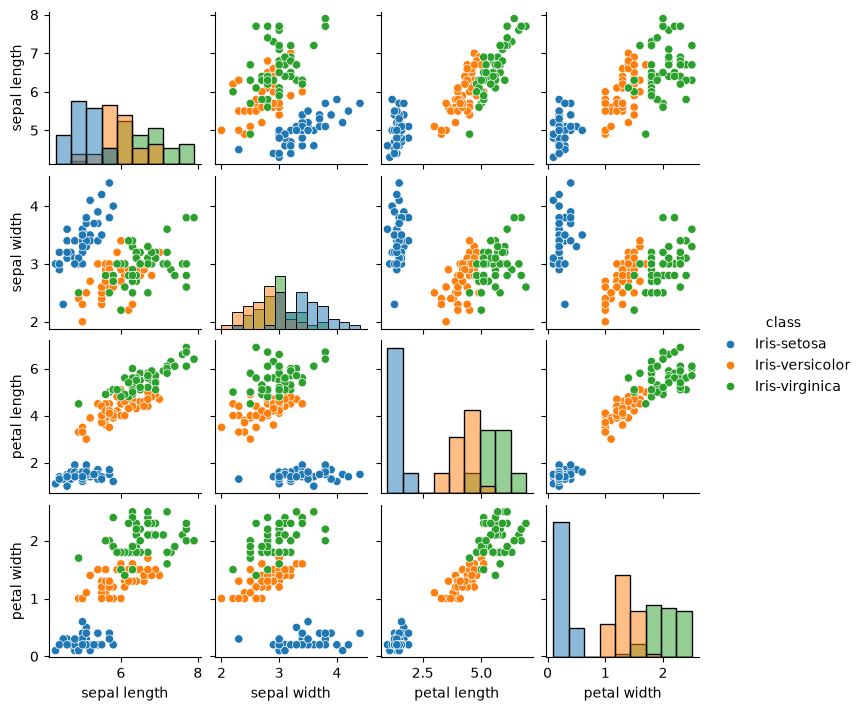

In [5]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = X.copy()
plot_df["class"] = y
sns.pairplot(plot_df, hue="class", diag_kind="hist", height=1.8)
plt.show()


## Train and test split

Hold out 20% of the rows. Stratify so each species keeps the same share in both sets.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())


Train: 120 Test: 30
class
Iris-setosa        40
Iris-versicolor    40
Iris-virginica     40
Name: count, dtype: int64
class
Iris-setosa        10
Iris-versicolor    10
Iris-virginica     10
Name: count, dtype: int64


## Logistic regression

The four measurements are the inputs. A `StandardScaler` comes first: petal and sepal ranges differ, and logistic regression is sensitive to that scale. There are no missing values.


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=10000)),
    ]
)
model.fit(X_train, y_train)
print("Fitted logistic regression")



Fitted logistic regression


## Evaluate on the held-out set

Accuracy is scored on the 30 held-out flowers. The classification report and the confusion matrix show which species the model chooses.


Accuracy: 0.933



                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



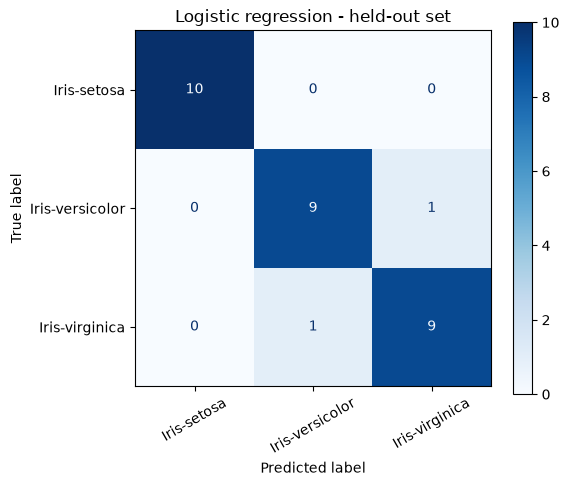

Misclassified held-out flowers:
- 1 Iris-versicolor predicted as Iris-virginica
- 1 Iris-virginica predicted as Iris-versicolor


In [8]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)

y_pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred))

labels = list(model.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    ax=ax,
    cmap="Blues",
    xticks_rotation=30,
)
ax.set_title("Logistic regression - held-out set")
fig.tight_layout()
plt.show()

cm = confusion_matrix(y_test, y_pred, labels=labels)
confused = []
for i, true_label in enumerate(labels):
    for j, pred_label in enumerate(labels):
        if i != j and cm[i, j] > 0:
            confused.append(
                f"{int(cm[i, j])} {true_label} predicted as {pred_label}"
            )

if confused:
    print("Misclassified held-out flowers:")
    for line in confused:
        print("-", line)
else:
    print("Every held-out flower was classified as its true species.")



## What the baseline catches

On the 30 held-out flowers, accuracy is 0.933. Every setosa is correct. One versicolor is called virginica, and one virginica is called versicolor. Precision and recall for those two species are 0.90.


## K-nearest neighbors and a decision tree

Both are fit on the same 120 training flowers.

K-nearest neighbors (k = 5) sits behind a `StandardScaler`, like the logistic regression. It depends on the numeric size of the measurements, and petal and sepal ranges differ. The decision tree splits one measurement at a time, so scaling does not change its cuts. `random_state=42` keeps that tree reproducible.


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

neighbors = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5)),
    ]
)
tree = DecisionTreeClassifier(random_state=42)
neighbors.fit(X_train, y_train)
tree.fit(X_train, y_train)

models = {
    "Logistic regression": model,
    "K-nearest neighbors": neighbors,
    "Decision tree": tree,
}

for name in models:
    print(f"Fitted {name}")


Fitted Logistic regression
Fitted K-nearest neighbors
Fitted Decision tree


## Compare on the held-out set

The same 30 flowers are scored again. Each model gets accuracy, a classification report, and a confusion matrix.


Logistic regression
Accuracy: 0.933

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



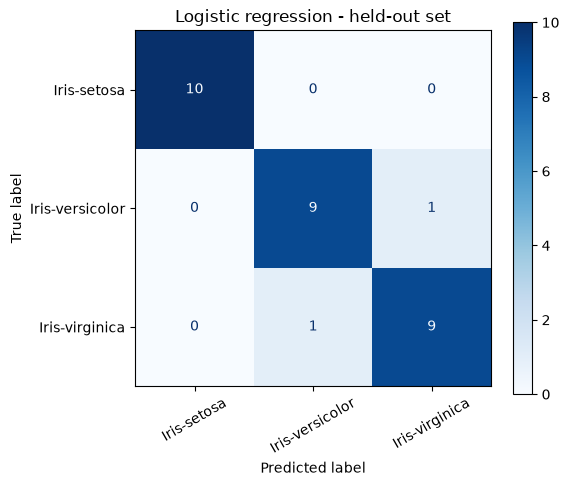

Misclassified held-out flowers:
- 1 Iris-versicolor predicted as Iris-virginica
- 1 Iris-virginica predicted as Iris-versicolor

K-nearest neighbors
Accuracy: 0.933

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



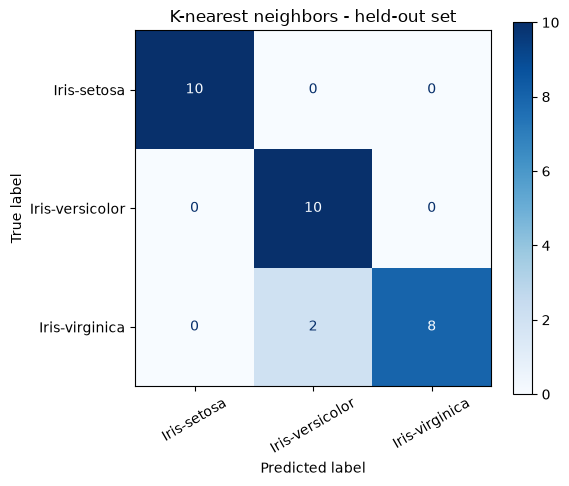

Misclassified held-out flowers:
- 2 Iris-virginica predicted as Iris-versicolor

Decision tree
Accuracy: 0.933

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



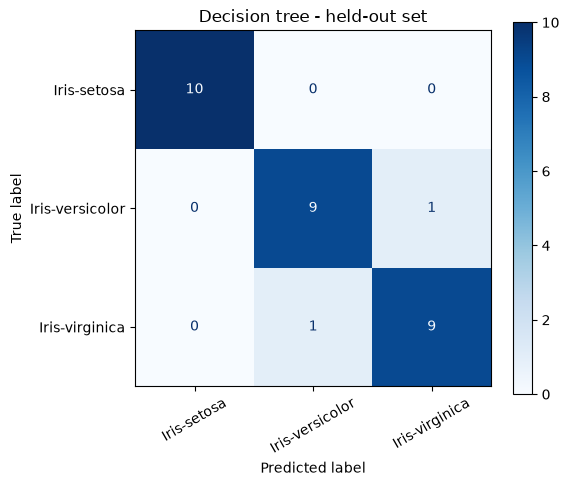

Misclassified held-out flowers:
- 1 Iris-versicolor predicted as Iris-virginica
- 1 Iris-virginica predicted as Iris-versicolor



In [10]:
for name, candidate in models.items():
    y_pred = candidate.predict(X_test)
    print(name)
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
    print()
    print(classification_report(y_test, y_pred))

    labels = list(candidate.classes_)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=labels,
        ax=ax,
        cmap="Blues",
        xticks_rotation=30,
    )
    ax.set_title(f"{name} - held-out set")
    fig.tight_layout()
    plt.show()

    cm = confusion_matrix(y_test, y_pred, labels=labels)
    confused = []
    for i, true_label in enumerate(labels):
        for j, pred_label in enumerate(labels):
            if i != j and cm[i, j] > 0:
                confused.append(
                    f"{int(cm[i, j])} {true_label} predicted as {pred_label}"
                )

    if confused:
        print("Misclassified held-out flowers:")
        for line in confused:
            print("-", line)
    else:
        print("Every held-out flower was classified as its true species.")
    print()


## Who performs better

On the same 30 flowers each model scores 0.933.

Logistic regression and the decision tree each miss one versicolor and one virginica. K-nearest neighbors calls every versicolor correctly and misses two virginica, both called versicolor. Every setosa is correct in all three.


## Cross-validation

The 30 held-out flowers stay unused here. Stratified 5-fold cross-validation resplits only the 120 training rows: each fold trains on 96 flowers and scores 24, with the same number of each species in every fold. The scaler is fit inside the fold, on that fold's training rows only.


Stratified 5-fold accuracy on the 120 training flowers

Logistic regression
  folds: 0.958, 1.000, 0.958, 0.958, 0.917
  mean:  0.958   std: 0.026



K-nearest neighbors
  folds: 0.958, 1.000, 0.958, 0.917, 0.958
  mean:  0.958   std: 0.026

Decision tree
  folds: 0.958, 0.958, 0.958, 0.958, 0.917
  mean:  0.950   std: 0.017



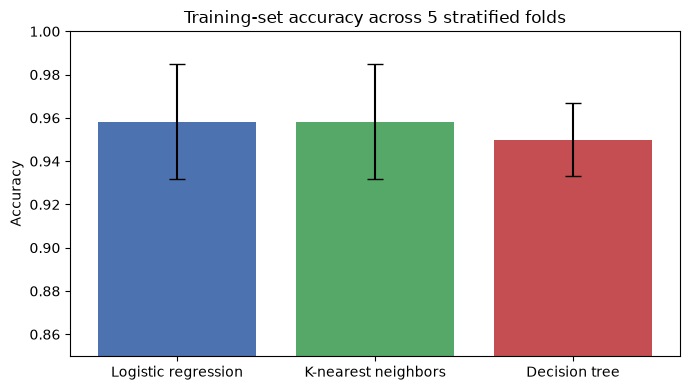

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Stratified 5-fold accuracy on the 120 training flowers")
print()

cv_means = []
cv_stds = []
cv_names = []
for name, candidate in models.items():
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="accuracy")
    cv_names.append(name)
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    folds = ", ".join(f"{score:.3f}" for score in scores)
    print(name)
    print(f"  folds: {folds}")
    print(f"  mean:  {scores.mean():.3f}   std: {scores.std():.3f}")
    print()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cv_names, cv_means, yerr=cv_stds, capsize=6, color=["#4C72B0", "#55A868", "#C44E52"])
ax.set_ylim(0.85, 1.0)
ax.set_ylabel("Accuracy")
ax.set_title("Training-set accuracy across 5 stratified folds")
fig.tight_layout()
plt.show()


## Conclusion

The data are 150 iris flowers, four measurements in centimeters, and three species, fifty of each. Thirty flowers are held out.

Logistic regression is the baseline. It is scaled, and on the 30 held-out flowers it scores 0.933. Every setosa is correct. One versicolor is called virginica, and one virginica is called versicolor.

K-nearest neighbors (k = 5), also scaled, and a decision tree are fit on the same 120 training flowers. On the held-out flowers each scores 0.933. The neighbors model misses two virginica, both called versicolor. The tree misses one versicolor and one virginica. Every setosa is correct in all three.

On the training flowers, stratified 5-fold accuracy is 0.958 for logistic regression, 0.958 for k-nearest neighbors, and 0.950 for the decision tree.

